In [1]:
#| echo: false
#| warning: false
#| output: asis

from IPython.display import Markdown, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.iolib.summary2 import summary_col

# Не показывать Warning
import warnings
warnings.simplefilter(action='ignore', category=Warning)

# Настройки оформления графиков
plt.rcParams['figure.figsize'] = (8.5, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

CONST_NAMES = ('const', 'Intercept')


def fmt(x, decimals=3):
    """Число с заданным числом знаков; оценка, которая округляется до нуля, — с тремя значащими цифрами."""
    if pd.isna(x):
        return ''
    text = f'{x:.{decimals}f}'
    if float(text) == 0:
        return f'{x:.3g}' if x != 0 else f'{0:.{decimals}f}'
    return text


def fmt_p(p, decimals=3):
    """P-значение: меньше 0.001 печатается как «<0.001»."""
    return '<0.001' if p < 0.001 else f'{p:.{decimals}f}'


def errors_text(res, case='nom'):
    """Название типа стандартных ошибок подгонки: 'nom' — «неробастные», 'dat' — «по неробастным …»."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    if cov_type == 'nonrobust':
        return {'nom': 'неробастные стандартные ошибки',
                'dat': 'по неробастным стандартным ошибкам'}[case]
    return {'nom': f'робастные стандартные ошибки, {cov_type}',
            'dat': f'по робастным стандартным ошибкам {cov_type}'}[case]


def fit_ols(formula, data, robust=False, **kwargs):
    """МНК-подгонка; robust=True — робастные ошибки HC3. Всегда t- и F-распределения (use_t=True)."""
    cov_type = 'HC3' if robust else 'nonrobust'
    return ols(formula, data=data).fit(cov_type=cov_type, use_t=True, **kwargs)


def show_table(df, index=True, align=None):
    """Таблица pandas в Markdown; числа должны быть заранее превращены в строки через fmt."""
    display(Markdown('\n\n' + df.to_markdown(index=index, colalign=align, disable_numparse=True) + '\n\n'))


def nobs_text(res):
    """Строка «Модель была подогнана по N наблюдениям»."""
    n = int(res.nobs)
    word = 'наблюдению' if n % 10 == 1 and n % 100 != 11 else 'наблюдениям'
    return f'Модель была подогнана по {n} {word}.'


def show_coefs(res, decimals=3, show_nobs=True):
    """Оценки коэффициентов: вертикальная таблица «Переменная | Оценка» и число наблюдений."""
    cov_type = getattr(res, 'cov_type', 'nonrobust')
    column = 'Оценка' if cov_type == 'nonrobust' else f'Оценка ({cov_type})'
    table = pd.DataFrame({'Переменная': res.params.index,
                          column: [fmt(b, decimals) for b in res.params]})
    text = table.to_markdown(index=False, colalign=('left', 'right'), disable_numparse=True)
    if show_nobs:
        text += '\n\n' + nobs_text(res)
    display(Markdown('\n\n' + text + '\n\n'))


def display_answer(text, use_callout=True, theme='note', title='Критическое значение'):
    """Ответ в рамке (callout): theme='note' — число, 'tip' — вывод, 'important' — условие."""
    if use_callout:
        head = f'title="{title}" ' if title else ''
        output_md = f'\n\n::: {{.callout-{theme} {head}icon="true"}}\n{text}\n:::\n\n'
    elif title:
        output_md = f'\n\n**{title}:** {text}\n\n'
    else:
        output_md = f'\n\n{text}\n\n'
    display(Markdown(output_md))


def show_conditions(level, errors=None, hypothesis=None, extra=()):
    """Блок «Условия теста»: уровень значимости (доля или список долей), тип ошибок, гипотеза формулой."""
    levels = level if isinstance(level, (list, tuple)) else [level]
    items = ['уровень значимости: **' + ' и '.join(f'{a * 100:g}%' for a in levels) + '**']
    if errors:
        items.append(f'стандартные ошибки: **{errors}**')
    hypotheses = [hypothesis] if isinstance(hypothesis, str) else list(hypothesis or [])
    if len(hypotheses) == 1:
        items.append(f'гипотеза: {hypotheses[0]}')
    else:
        items += [f'гипотеза {i}: {h}' for i, h in enumerate(hypotheses, start=1)]
    items += list(extra)
    display_answer('\n'.join(f'- {item}' for item in items), theme='important', title='Условия теста')


def signif_stars(p):
    """Коды значимости: *** p<0.01, ** p<0.05, * p<0.1."""
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''


SIGNIF_LEGEND = '*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$'


def print_regression_summary(res, decimals=3, show_signif=True):
    """Таблица t-теста: Coef., Std.Err., t-value, p-value, Signif. Заголовок называет тип ошибок."""
    title = f'**Результаты $t$-теста для коэффициентов ({errors_text(res)}):**'
    table = pd.DataFrame({
        'Coef.': [fmt(b, decimals) for b in res.params],
        'Std.Err.': [fmt(s, decimals) for s in res.bse],
        't-value': [fmt(t, decimals) for t in res.tvalues],
        'p-value': [fmt_p(p, decimals) for p in res.pvalues],
    }, index=res.params.index)
    legend = ''
    if show_signif:
        table['Signif.'] = ['' if name in CONST_NAMES else signif_stars(p)
                            for name, p in res.pvalues.items()]
        legend = '\n\n' + SIGNIF_LEGEND
    align = ('left',) + ('right',) * 4 + (('left',) if show_signif else ())
    display(Markdown(f'\n\n{title}\n\n' + table.to_markdown(colalign=align, disable_numparse=True) + legend + '\n\n'))


def print_significant_coeffs(res, sign_level=0.05, theme='note', title=None):
    """Рамка со списком коэффициентов, значимых на уровне sign_level (без константы)."""
    names = [name for name, p in res.pvalues.items() if p < sign_level and name not in CONST_NAMES]
    if title is None:
        title = f'Коэффициенты, значимые на уровне {sign_level * 100:g}% ({errors_text(res, "dat")})'
    text = ', '.join(f'`{name}`' for name in names) if names else 'Значимых коэффициентов не выявлено.'
    display_answer(text, theme=theme, title=title)


def show_models(models, names=None, decimals=3, regressor_order=(), errors_note=None, info=None):
    """Сравнение регрессий (summary_col): строка Dep. Variable, коды значимости, пояснение про скобки.

    info — словарь {название строки: функция от подгонки} для дополнительных строк (N, F и т. п.).
    """
    table = summary_col(models, model_names=names, stars=True, float_format=f'%0.{decimals}f',
                        regressor_order=list(regressor_order), info_dict=info or {}).tables[0]
    top = pd.DataFrame({col: [m.model.endog_names] for col, m in zip(table.columns, models)},
                       index=['Dep. Variable'])
    table = pd.concat([top, table])
    if errors_note is None:
        errors_note = errors_text(models[0])
    note = f'{SIGNIF_LEGEND}. В скобках — {errors_note}.'
    display(Markdown('\n\n' + table.to_markdown(disable_numparse=True) + '\n\n' + note + '\n\n'))


def show_ci(res, level=0.95, decimals=3):
    """Доверительные интервалы: «Переменная | Нижняя граница | Верхняя граница», заголовок над таблицей."""
    ci = res.conf_int(alpha=1 - level)
    table = pd.DataFrame({'Переменная': ci.index,
                          'Нижняя граница': [fmt(x, decimals) for x in ci[0]],
                          'Верхняя граница': [fmt(x, decimals) for x in ci[1]]})
    title = f'**{level * 100:g}%-е доверительные интервалы ({errors_text(res)}):**'
    display(Markdown(f'\n\n{title}\n\n'
                     + table.to_markdown(index=False, colalign=('left', 'right', 'right'), disable_numparse=True) + '\n\n'))

# ---- Данные и помощники листка 11 ----
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Временные ряды: наблюдения упорядочены по времени
Icecream = pd.read_csv('../datasets/Icecream.csv')
Consumption = pd.read_csv('../datasets/Consumption.csv')
Mishkin = pd.read_csv('../datasets/Mishkin.csv')
Tbrate = pd.read_csv('../datasets/Tbrate.csv')
MoneyUS = pd.read_csv('../datasets/MoneyUS.csv')
Macrodat = pd.read_csv('../datasets/Macrodat.csv')

# Спецификации в записи statsmodels; x.diff() — первая разность
# (первое наблюдение разности — пропуск, при подгонке отбрасывается)
F_ICECREAM = 'cons ~ income + price + temp'
F_CONSUMPTION = 'np.log(yd).diff() ~ np.log(ce).diff()'
F_MISHKIN = 'pai3.diff() ~ tb3.diff() + np.log(cpi).diff()'
F_TBRATE = 'pi.diff() ~ y.diff() + r.diff()'
F_MONEYUS = 'infl.diff() ~ y.diff() + tbr.diff() + cpr.diff() + m.diff()'
F_MACRODAT = ('lhur.diff() ~ np.log(punew).diff() + fyff.diff() + fygm3.diff() +'
              ' fygt1.diff() + np.log(gdpjp).diff()')

# MoneyUS: оценки порядка 0.0001–0.001, при трёх знаках они превращаются в нули
DEC_MONEYUS = 5

# Границы d_L, d_U теста Дарбина–Уотсона — из таблицы критических значений курса
# (tables/dw-critical-values.csv; точный расчёт, см. tables/dw_critical_values.py).
# Ключ: уровень значимости, число наблюдений, число регрессоров без константы.
DW_TABLE = pd.read_csv('../tables/dw-critical-values.csv').set_index(['alpha', 'n', 'k'])


def nw_lags(n):
    """Число лагов для HAC-ошибок по правилу Ньюи–Уэста: целая часть 4 (n/100)^(2/9)."""
    return int(4 * (n / 100) ** (2 / 9))


def fit_hac(formula, data, maxlags):
    """МНК-подгонка с HAC-ошибками statsmodels (Ньюи–Уэст, ядро Бартлетта), t-распределение."""
    return ols(formula, data=data).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags}, use_t=True)


def show_acorr_conditions(res, level, order):
    """Блок «Условия теста» для задач раздела 1: DW-тест и BG-тест порядка order."""
    n, k = int(res.nobs), int(res.df_model)
    rho = '='.join(rf'\rho_{j}' for j in range(1, order + 1)) + '=0'
    show_conditions(level, extra=[
        r'тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); '
        f'границы $d_L$, $d_U$ — для числа наблюдений $n={n}$ и числа регрессоров без константы $k={k}$',
        f'тест Бройша–Годфри порядка {order}, LM-статистика: гипотеза $H_0:{rho}$ '
        f'(серийной корреляции порядка {order} нет); '
        f'критическое значение — по распределению $\\chi^2$ с числом степеней свободы {order}'])


def show_dw_test(res, level):
    """Ответ по DW-тесту: таблица (DW, d_L, d_U) и вывод. Возвращает True, если H0 отвергнута,
    False — если не отвергнута, None — в зоне неопределённости."""
    dw = durbin_watson(res.resid)
    d_l, d_u = DW_TABLE.loc[(level, int(res.nobs), int(res.df_model))]
    show_table(pd.DataFrame({'DW': [f'{dw:.3f}'], '$d_L$': [f'{d_l:.3f}'], '$d_U$': [f'{d_u:.3f}']}),
               index=False, align=('right',) * 3)
    if dw < d_l:
        reject = True
        text = (f'$DW = {dw:.3f} < d_L = {d_l:.3f}$, гипотеза $H_0$ отвергается: '
                'положительная автокорреляция первого порядка.')
    elif dw > 4 - d_l:
        reject = True
        text = (f'$DW = {dw:.3f} > 4 - d_L = {4 - d_l:.3f}$, гипотеза $H_0$ отвергается: '
                'отрицательная автокорреляция первого порядка.')
    elif d_u < dw < 4 - d_u:
        reject = False
        text = (f'$d_U = {d_u:.3f} < DW = {dw:.3f} < 4 - d_U = {4 - d_u:.3f}$, '
                'гипотеза $H_0$ не отвергается.')
    else:
        reject = None
        text = f'$DW = {dw:.3f}$ попадает в зону неопределённости: тест не даёт ответа.'
    display_answer(text, theme='tip', title='Вывод (DW-тест)')
    return reject


def show_bg(res, order):
    """Таблица теста Бройша–Годфри из одной строки: LM, df, P-значение."""
    lm, pvalue = acorr_breusch_godfrey(res, nlags=order)[:2]
    show_table(pd.DataFrame({'LM-статистика': [fmt(lm, 3)], 'Степени свободы': [order],
                             'P-значение': [fmt_p(pvalue)]}), index=False, align=('right',) * 3)


def show_bg_conclusion(res, order, level, dw_reject=None):
    """Вывод по BG-тесту; если он расходится с выводом DW-теста, это сказано отдельной фразой."""
    lm = acorr_breusch_godfrey(res, nlags=order)[0]
    crit = stats.chi2.ppf(1 - level, df=order)
    reject = lm > crit
    if reject:
        text = (f'$LM = {lm:.3f} > {crit:.2f}$, гипотеза $H_0$ отвергается: '
                f'серийная корреляция порядка {order} есть.')
    else:
        text = (f'$LM = {lm:.3f} < {crit:.2f}$, гипотеза $H_0$ не отвергается: '
                f'серийная корреляция порядка {order} не выявлена.')
    if dw_reject is not None and dw_reject != reject:
        said = {True: 'отвергает', False: 'не отвергает'}
        text += (f' Выводы двух тестов расходятся: DW-тест гипотезу об отсутствии автокорреляции '
                 f'{said[dw_reject]}, а BG-тест порядка {order} на уровне {level * 100:g}% {said[reject]}.')
    display_answer(text, theme='tip', title='Вывод (BG-тест)')


def show_hac_conditions(res, level):
    """Блок «Условия теста» для задач раздела 2: уровень, типы ошибок, правило и число лагов."""
    n = int(res.nobs)
    show_conditions(
        level,
        errors=f'неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = {nw_lags(n)}`',
        hypothesis=r'$H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя',
        extra=[r'число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = ' + f'{nw_lags(n)}$ при $n={n}$'])


def plot_resid(res):
    """Остатки во времени и зависимость остатка от предыдущего (с подогнанной прямой)."""
    e = res.resid.to_numpy()
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
    axes[0].plot(np.arange(len(e)), e, marker='o', markersize=3, linewidth=1)
    axes[0].axhline(0, color='gray', linewidth=0.8)
    axes[0].set_xlabel('Номер наблюдения $t$')
    axes[0].set_ylabel('Остаток $e_t$')
    slope, intercept = np.polyfit(e[:-1], e[1:], 1)
    grid = np.array([e[:-1].min(), e[:-1].max()])
    axes[1].scatter(e[:-1], e[1:], s=15)
    axes[1].plot(grid, intercept + slope * grid, color='tab:red', linestyle='--',
                 label=f'наклон {slope:.2f}')
    axes[1].set_xlabel('Остаток $e_{t-1}$')
    axes[1].set_ylabel('Остаток $e_t$')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

::: {.callout-important title="Важно"}
- Логарифм натуральный; константа включается в модель по умолчанию.
- Все наборы данных — временные ряды, наблюдения упорядочены по времени. Данные лежат в `datasets/`, описание переменных — в `datasets/data-description.md`.
- Запись моделей — как в формулах statsmodels, её можно скопировать в `ols`: `Intercept` — константа, `np.log(x)` — $\log x$, `x.diff()` — первая разность $x_t - x_{t-1}$, `np.log(x).diff()` — первая разность логарифма $\log x_t - \log x_{t-1}$. У первого наблюдения разности нет, поэтому при подгонке оно теряется.
- Статистики и стандартные ошибки округляются до 3-х десятичных знаков, критические значения — до 2-х. Ответы считаются по неокруглённым оценкам.
- Тест Дарбина–Уотсона: статистика — `durbin_watson(res.resid)`. Границы $d_L$, $d_U$ берутся из таблицы критических значений [`tables/dw-critical-values.md`](../tables/dw-critical-values.md) для уровня значимости из условия, числа наблюдений $n$ и числа регрессоров без константы $k$. При $DW < d_L$ гипотеза $H_0$ отвергается в пользу положительной автокорреляции, при $DW > 4 - d_L$ — в пользу отрицательной; при $d_U < DW < 4 - d_U$ гипотеза не отвергается; в остальных случаях тест не даёт ответа.
- Тест Бройша–Годфри: `acorr_breusch_godfrey(res, nlags=p)`, LM-статистика; порядок `p` указан в условии.
- Робастные стандартные ошибки — HAC (Ньюи–Уэст, ядро Бартлетта): `ols(…).fit(cov_type='HAC', cov_kwds={'maxlags': L}, use_t=True)`. Число лагов $L=\lfloor 4\,(n/100)^{2/9}\rfloor$, где $n$ — число наблюдений в подгонке; оно указано в условии. Критические значения и P-значения t-теста — по t-распределению.
- Значимость константы не обсуждается: в списки значимых коэффициентов `Intercept` не входит.
:::

# Диагностика модели: тесты на серийную корреляцию

## ice cream equation

Для набора данных `Icecream` рассмотрим регрессию **cons на income, price, temp**.

Переменные: `cons` — потребление мороженого на душу населения (в пинтах), `income` — средний недельный доход семьи (в долларах США), `price` — цена пинты мороженого, `temp` — средняя температура (в градусах Фаренгейта). Наблюдения — четырёхнедельные, США, 1951–1953 гг.

Результаты оценивания:

In [2]:
#| output: asis
res = fit_ols(F_ICECREAM, Icecream)
show_coefs(res)
show_acorr_conditions(res, 0.05, 1)



| Переменная   |   Оценка |
|:-------------|---------:|
| Intercept    |    0.197 |
| income       |    0.003 |
| price        |   -1.044 |
| temp         |    0.003 |

Модель была подогнана по 30 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=30$ и числа регрессоров без константы $k=3$
- тест Бройша–Годфри порядка 1, LM-статистика: гипотеза $H_0:\rho_1=0$ (серийной корреляции порядка 1 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 1
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [3]:
#| output: asis
dw_reject = show_dw_test(res, 0.05)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 1.021 |   1.214 |   1.650 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 1.021 < d_L = 1.214$, гипотеза $H_0$ отвергается: положительная автокорреляция первого порядка.
:::



Остатки модели показывает @fig-icecream-resid: соседние остатки связаны положительно.

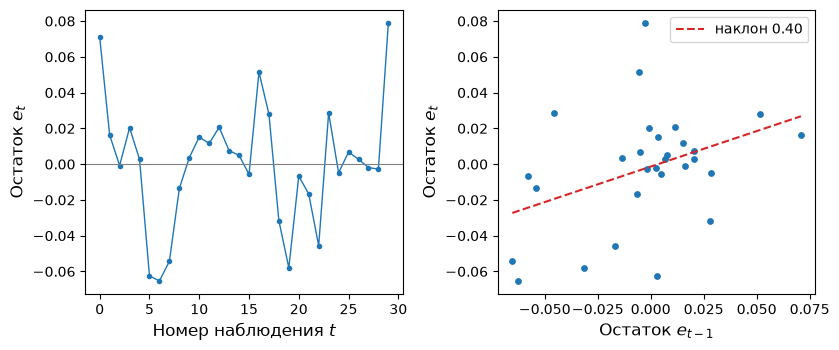

In [4]:
#| label: fig-icecream-resid
#| fig-cap: "ice cream equation: остатки модели во времени и зависимость остатка от предыдущего"
#| fig-align: "center"
plot_resid(res)

**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 1.

In [5]:
#| output: asis
show_bg(res, 1)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|           4.237 |                 1 |        0.040 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [6]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.05, df=1):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 3.84$
:::



Какой можно сделать вывод?

In [7]:
#| output: asis
show_bg_conclusion(res, 1, 0.05, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 4.237 > 3.84$, гипотеза $H_0$ отвергается: серийная корреляция порядка 1 есть.
:::



## consumption equation

Для набора данных `Consumption` рассмотрим регрессию **np.log(yd).diff() на np.log(ce).diff()**.

Переменные: `yd` — располагаемый личный доход, `ce` — личные потребительские расходы (оба ряда — в долларах 1986 г.). Наблюдения — квартальные, Канада, 1947–1996 гг.

Результаты оценивания:

In [8]:
#| output: asis
res = fit_ols(F_CONSUMPTION, Consumption)
show_coefs(res)
show_acorr_conditions(res, 0.01, 2)



| Переменная        |   Оценка |
|:------------------|---------:|
| Intercept         |    0.006 |
| np.log(ce).diff() |    0.371 |

Модель была подогнана по 199 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=199$ и числа регрессоров без константы $k=1$
- тест Бройша–Годфри порядка 2, LM-статистика: гипотеза $H_0:\rho_1=\rho_2=0$ (серийной корреляции порядка 2 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 2
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [9]:
#| output: asis
dw_reject = show_dw_test(res, 0.01)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 2.382 |   1.663 |   1.683 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 2.382 > 4 - d_L = 2.337$, гипотеза $H_0$ отвергается: отрицательная автокорреляция первого порядка.
:::



**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 2.

In [10]:
#| output: asis
show_bg(res, 2)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|           8.913 |                 2 |        0.012 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [11]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.01, df=2):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 9.21$
:::



Какой можно сделать вывод?

In [12]:
#| output: asis
show_bg_conclusion(res, 2, 0.01, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 8.913 < 9.21$, гипотеза $H_0$ не отвергается: серийная корреляция порядка 2 не выявлена. Выводы двух тестов расходятся: DW-тест гипотезу об отсутствии автокорреляции отвергает, а BG-тест порядка 2 на уровне 1% не отвергает.
:::



## inflation equation #1

Для набора данных `Mishkin` рассмотрим регрессию **pai3.diff() на tb3.diff(), np.log(cpi).diff()**.

Переменные: `pai3` — трёхмесячный темп инфляции (в процентах годовых), `tb3` — ставка по трёхмесячным казначейским векселям (в процентах годовых), `cpi` — индекс потребительских цен (среднее за 1982–1984 гг. равно 100). Наблюдения — месячные, США, 1950–1990 гг.

Результаты оценивания:

In [13]:
#| output: asis
res = fit_ols(F_MISHKIN, Mishkin)
show_coefs(res)
show_acorr_conditions(res, 0.01, 2)



| Переменная         |   Оценка |
|:-------------------|---------:|
| Intercept          |    0.162 |
| tb3.diff()         |    0.081 |
| np.log(cpi).diff() |  -44.823 |

Модель была подогнана по 490 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=490$ и числа регрессоров без константы $k=2$
- тест Бройша–Годфри порядка 2, LM-статистика: гипотеза $H_0:\rho_1=\rho_2=0$ (серийной корреляции порядка 2 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 2
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [14]:
#| output: asis
dw_reject = show_dw_test(res, 0.01)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 1.621 |   1.782 |   1.799 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 1.621 < d_L = 1.782$, гипотеза $H_0$ отвергается: положительная автокорреляция первого порядка.
:::



**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 2.

In [15]:
#| output: asis
show_bg(res, 2)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|          17.200 |                 2 |       <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [16]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.01, df=2):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 9.21$
:::



Какой можно сделать вывод?

In [17]:
#| output: asis
show_bg_conclusion(res, 2, 0.01, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 17.200 > 9.21$, гипотеза $H_0$ отвергается: серийная корреляция порядка 2 есть.
:::



## inflation equation #2

Для набора данных `Tbrate` рассмотрим регрессию **pi.diff() на y.diff(), r.diff()**.

Переменные: `pi` — темп инфляции, `y` — логарифм реального ВВП, `r` — ставка по 91-дневным казначейским векселям. Наблюдения — квартальные, Канада, 1950–1996 гг.

Результаты оценивания:

In [18]:
#| output: asis
res = fit_ols(F_TBRATE, Tbrate)
show_coefs(res)
show_acorr_conditions(res, 0.05, 1)



| Переменная   |   Оценка |
|:-------------|---------:|
| Intercept    |    0.091 |
| y.diff()     |   -9.130 |
| r.diff()     |    0.311 |

Модель была подогнана по 187 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=187$ и числа регрессоров без константы $k=2$
- тест Бройша–Годфри порядка 1, LM-статистика: гипотеза $H_0:\rho_1=0$ (серийной корреляции порядка 1 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 1
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [19]:
#| output: asis
dw_reject = show_dw_test(res, 0.05)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 2.459 |   1.739 |   1.782 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 2.459 > 4 - d_L = 2.261$, гипотеза $H_0$ отвергается: отрицательная автокорреляция первого порядка.
:::



**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 1.

In [20]:
#| output: asis
show_bg(res, 1)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|          10.683 |                 1 |        0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [21]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.05, df=1):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 3.84$
:::



Какой можно сделать вывод?

In [22]:
#| output: asis
show_bg_conclusion(res, 1, 0.05, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 10.683 > 3.84$, гипотеза $H_0$ отвергается: серийная корреляция порядка 1 есть.
:::



## inflation equation #3

Для набора данных `MoneyUS` рассмотрим регрессию

`infl.diff() ~ y.diff() + tbr.diff() + cpr.diff() + m.diff()`

Переменные: `infl` — квартальный темп инфляции (в процентах годовых), `y` — логарифм реального ВВП, `tbr` — ставка по казначейским векселям, `cpr` — ставка по коммерческим бумагам (в процентах годовых), `m` — логарифм реальной денежной массы M1. Наблюдения — квартальные, США, 1954–1994 гг.

Результаты оценивания (оценки в этой задаче малы по величине, поэтому приведены с 5 десятичными знаками):

In [23]:
#| output: asis
res = fit_ols(F_MONEYUS, MoneyUS)
show_coefs(res, decimals=DEC_MONEYUS)
show_acorr_conditions(res, 0.01, 2)



| Переменная   |   Оценка |
|:-------------|---------:|
| Intercept    | -0.00013 |
| y.diff()     | -0.00241 |
| tbr.diff()   |  0.00017 |
| cpr.diff()   |  0.40710 |
| m.diff()     | -0.00124 |

Модель была подогнана по 163 наблюдениям.





::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=163$ и числа регрессоров без константы $k=4$
- тест Бройша–Годфри порядка 2, LM-статистика: гипотеза $H_0:\rho_1=\rho_2=0$ (серийной корреляции порядка 2 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 2
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [24]:
#| output: asis
dw_reject = show_dw_test(res, 0.01)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 0.834 |   1.590 |   1.689 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 0.834 < d_L = 1.590$, гипотеза $H_0$ отвергается: положительная автокорреляция первого порядка.
:::



Остатки модели показывает @fig-moneyus-resid: соседние остатки связаны положительно.

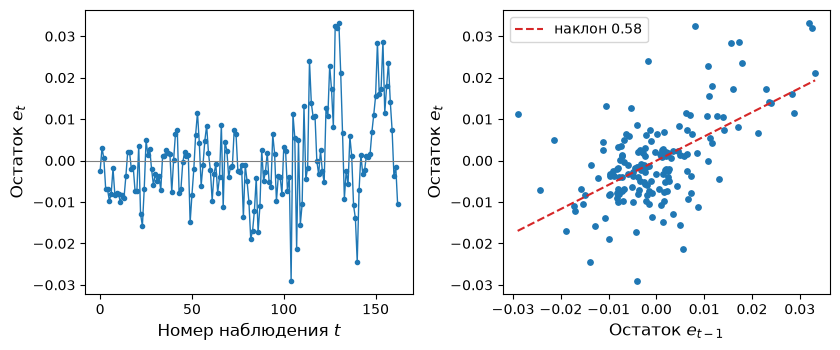

In [25]:
#| label: fig-moneyus-resid
#| fig-cap: "inflation equation #3: остатки модели во времени и зависимость остатка от предыдущего"
#| fig-align: "center"
plot_resid(res)

**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 2.

In [26]:
#| output: asis
show_bg(res, 2)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|          61.893 |                 2 |       <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [27]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.01, df=2):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 9.21$
:::



Какой можно сделать вывод?

In [28]:
#| output: asis
show_bg_conclusion(res, 2, 0.01, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 61.893 > 9.21$, гипотеза $H_0$ отвергается: серийная корреляция порядка 2 есть.
:::



## unemployment equation

Для набора данных `Macrodat` рассмотрим регрессию

```python
lhur.diff() ~ np.log(punew).diff() + fyff.diff() + fygm3.diff() +
              fygt1.diff() + np.log(gdpjp).diff()
```

Переменные: `lhur` — уровень безработицы (в процентах), `punew` — индекс потребительских цен, `fyff` — ставка по федеральным фондам, `fygm3` и `fygt1` — ставки по трёхмесячным и годовым казначейским бумагам, `gdpjp` — реальный ВВП Японии. Наблюдения — квартальные, США, 1959–2000 гг.

Результаты оценивания:

In [29]:
#| output: asis
res = fit_ols(F_MACRODAT, Macrodat)
show_coefs(res)



| Переменная           |   Оценка |
|:---------------------|---------:|
| Intercept            |   -0.141 |
| np.log(punew).diff() |   12.720 |
| fyff.diff()          |   -0.115 |
| fygm3.diff()         |    0.168 |
| fygt1.diff()         |   -0.166 |
| np.log(gdpjp).diff() |   -0.399 |

Модель была подогнана по 161 наблюдению.



В наборе 168 кварталов; последние 6 значений `gdpjp` пропущены, ещё одно наблюдение теряется при взятии разности.

In [30]:
#| output: asis
show_acorr_conditions(res, 0.01, 2)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- тест Дарбина–Уотсона: гипотеза $H_0:\rho=0$ (автокорреляции первого порядка нет); границы $d_L$, $d_U$ — для числа наблюдений $n=161$ и числа регрессоров без константы $k=5$
- тест Бройша–Годфри порядка 2, LM-статистика: гипотеза $H_0:\rho_1=\rho_2=0$ (серийной корреляции порядка 2 нет); критическое значение — по распределению $\chi^2$ с числом степеней свободы 2
:::



**DW-тест.** Вычислите тестовую статистику. Найдите критические значения $d_L$, $d_U$. Какой можно сделать вывод? **Статистику округлите до 3-х десятичных знаков.**

In [31]:
#| output: asis
dw_reject = show_dw_test(res, 0.01)



|    DW |   $d_L$ |   $d_U$ |
|------:|--------:|--------:|
| 1.063 |   1.574 |   1.701 |





::: {.callout-tip title="Вывод (DW-тест)" icon="true"}
$DW = 1.063 < d_L = 1.574$, гипотеза $H_0$ отвергается: положительная автокорреляция первого порядка.
:::



**LM/BG-тест.** Проверьте модель на серийную корреляцию порядка 2.

In [32]:
#| output: asis
show_bg(res, 2)



|   LM-статистика |   Степени свободы |   P-значение |
|----------------:|------------------:|-------------:|
|          35.658 |                 2 |       <0.001 |



Вычислите критическое значение. **Ответ округлите до 2-х десятичных знаков.**

In [33]:
#| output: asis
display_answer(f'$\\chi^2_{{crit}} = {stats.chi2.ppf(1 - 0.01, df=2):.2f}$')



::: {.callout-note title="Критическое значение" icon="true"}
$\chi^2_{crit} = 9.21$
:::



Какой можно сделать вывод?

In [34]:
#| output: asis
show_bg_conclusion(res, 2, 0.01, dw_reject)



::: {.callout-tip title="Вывод (BG-тест)" icon="true"}
$LM = 35.658 > 9.21$, гипотеза $H_0$ отвергается: серийная корреляция порядка 2 есть.
:::



# Робастный t-тест (HAC-ошибки)

## ice cream equation

Для набора данных `Icecream` рассмотрим регрессию **cons на income, price, temp**.

In [35]:
#| output: asis
res_ols = fit_ols(F_ICECREAM, Icecream)
res_hac = fit_hac(F_ICECREAM, Icecream, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.01)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 3`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 3$ при $n=30$
:::



In [36]:
#| output: asis
print_regression_summary(res_ols)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|           |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:----------|--------:|-----------:|----------:|----------:|:----------|
| Intercept |   0.197 |      0.270 |     0.730 |     0.472 |           |
| income    |   0.003 |      0.001 |     2.824 |     0.009 | ***       |
| price     |  -1.044 |      0.834 |    -1.252 |     0.222 |           |
| temp      |   0.003 |   0.000446 |     7.762 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [37]:
#| output: asis
print_significant_coeffs(res_ols, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`income`, `temp`
:::



In [38]:
#| output: asis
print_regression_summary(res_hac)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|           |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:----------|--------:|-----------:|----------:|----------:|:----------|
| Intercept |   0.197 |      0.314 |     0.627 |     0.536 |           |
| income    |   0.003 |      0.001 |     2.676 |     0.013 | **        |
| price     |  -1.044 |      0.910 |    -1.148 |     0.261 |           |
| temp      |   0.003 |   0.000373 |     9.282 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [39]:
#| output: asis
print_significant_coeffs(res_hac, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HAC)" icon="true"}
`temp`
:::



## consumption equation

Для набора данных `Consumption` рассмотрим регрессию **np.log(yd).diff() на np.log(ce).diff()**.

In [40]:
#| output: asis
res_ols = fit_ols(F_CONSUMPTION, Consumption)
res_hac = fit_hac(F_CONSUMPTION, Consumption, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.01)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 4`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 4$ при $n=199$
:::



In [41]:
#| output: asis
print_regression_summary(res_ols)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                   |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept         |   0.006 |      0.001 |     5.252 |    <0.001 |           |
| np.log(ce).diff() |   0.371 |      0.068 |     5.483 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [42]:
#| output: asis
print_significant_coeffs(res_ols, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`np.log(ce).diff()`
:::



In [43]:
#| output: asis
print_regression_summary(res_hac)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|                   |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept         |   0.006 |      0.001 |     4.943 |    <0.001 |           |
| np.log(ce).diff() |   0.371 |      0.079 |     4.668 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [44]:
#| output: asis
print_significant_coeffs(res_hac, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HAC)" icon="true"}
`np.log(ce).diff()`
:::



## inflation equation #1

Для набора данных `Mishkin` рассмотрим регрессию **pai3.diff() на tb3.diff(), np.log(cpi).diff()**.

In [45]:
#| output: asis
res_ols = fit_ols(F_MISHKIN, Mishkin)
res_hac = fit_hac(F_MISHKIN, Mishkin, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.01)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 5`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 5$ при $n=490$
:::



In [46]:
#| output: asis
print_regression_summary(res_ols)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                    |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept          |   0.162 |      0.087 |     1.860 |     0.063 |           |
| tb3.diff()         |   0.081 |      0.112 |     0.726 |     0.468 |           |
| np.log(cpi).diff() | -44.823 |     17.130 |    -2.617 |     0.009 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [47]:
#| output: asis
print_significant_coeffs(res_ols, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`np.log(cpi).diff()`
:::



In [48]:
#| output: asis
print_regression_summary(res_hac)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|                    |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept          |   0.162 |      0.075 |     2.156 |     0.032 |           |
| tb3.diff()         |   0.081 |      0.082 |     0.986 |     0.325 |           |
| np.log(cpi).diff() | -44.823 |     19.480 |    -2.301 |     0.022 | **        |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [49]:
#| output: asis
print_significant_coeffs(res_hac, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HAC)" icon="true"}
Значимых коэффициентов не выявлено.
:::



## inflation equation #2

Для набора данных `Tbrate` рассмотрим регрессию **pi.diff() на y.diff(), r.diff()**.

In [50]:
#| output: asis
res_ols = fit_ols(F_TBRATE, Tbrate)
res_hac = fit_hac(F_TBRATE, Tbrate, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.05)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **5%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 4`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 4$ при $n=187$
:::



In [51]:
#| output: asis
print_regression_summary(res_ols)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|           |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:----------|--------:|-----------:|----------:|----------:|:----------|
| Intercept |   0.091 |      0.187 |     0.488 |     0.626 |           |
| y.diff()  |  -9.130 |     12.400 |    -0.736 |     0.462 |           |
| r.diff()  |   0.311 |      0.156 |     1.990 |     0.048 | **        |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [52]:
#| output: asis
print_significant_coeffs(res_ols, 0.05)



::: {.callout-note title="Коэффициенты, значимые на уровне 5% (по неробастным стандартным ошибкам)" icon="true"}
`r.diff()`
:::



In [53]:
#| output: asis
print_regression_summary(res_hac)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|           |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:----------|--------:|-----------:|----------:|----------:|:----------|
| Intercept |   0.091 |      0.161 |     0.563 |     0.574 |           |
| y.diff()  |  -9.130 |     13.899 |    -0.657 |     0.512 |           |
| r.diff()  |   0.311 |      0.116 |     2.687 |     0.008 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [54]:
#| output: asis
print_significant_coeffs(res_hac, 0.05)



::: {.callout-note title="Коэффициенты, значимые на уровне 5% (по робастным стандартным ошибкам HAC)" icon="true"}
`r.diff()`
:::



## inflation equation #3

Для набора данных `MoneyUS` рассмотрим регрессию

`infl.diff() ~ y.diff() + tbr.diff() + cpr.diff() + m.diff()`

In [55]:
#| output: asis
res_ols = fit_ols(F_MONEYUS, MoneyUS)
res_hac = fit_hac(F_MONEYUS, MoneyUS, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.01)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 4`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 4$ при $n=163$
:::



Оценки в этой задаче малы по величине, поэтому таблицы приведены с 5 десятичными знаками.

In [56]:
#| output: asis
print_regression_summary(res_ols, decimals=DEC_MONEYUS)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|            |    Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-----------|---------:|-----------:|----------:|----------:|:----------|
| Intercept  | -0.00013 |    0.00110 |  -0.12168 |   0.90331 |           |
| y.diff()   | -0.00241 |    0.00260 |  -0.92798 |   0.35483 |           |
| tbr.diff() |  0.00017 |    0.00302 |   0.05510 |   0.95612 |           |
| cpr.diff() |  0.40710 |    0.09904 |   4.11063 |    <0.001 | ***       |
| m.diff()   | -0.00124 |    0.00049 |  -2.52660 |   0.01250 | **        |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [57]:
#| output: asis
print_significant_coeffs(res_ols, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`cpr.diff()`
:::



In [58]:
#| output: asis
print_regression_summary(res_hac, decimals=DEC_MONEYUS)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|            |    Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:-----------|---------:|-----------:|----------:|----------:|:----------|
| Intercept  | -0.00013 |    0.00159 |  -0.08400 |   0.93317 |           |
| y.diff()   | -0.00241 |    0.00292 |  -0.82599 |   0.41005 |           |
| tbr.diff() |  0.00017 |    0.00325 |   0.05116 |   0.95926 |           |
| cpr.diff() |  0.40710 |    0.09853 |   4.13172 |    <0.001 | ***       |
| m.diff()   | -0.00124 |    0.00035 |  -3.58564 |    <0.001 | ***       |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [59]:
#| output: asis
print_significant_coeffs(res_hac, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HAC)" icon="true"}
`cpr.diff()`, `m.diff()`
:::



## unemployment equation

Для набора данных `Macrodat` рассмотрим регрессию

```python
lhur.diff() ~ np.log(punew).diff() + fyff.diff() + fygm3.diff() +
              fygt1.diff() + np.log(gdpjp).diff()
```

In [60]:
#| output: asis
res_ols = fit_ols(F_MACRODAT, Macrodat)
res_hac = fit_hac(F_MACRODAT, Macrodat, maxlags=nw_lags(res_ols.nobs))
show_hac_conditions(res_ols, 0.01)



::: {.callout-important title="Условия теста" icon="true"}
- уровень значимости: **1%**
- стандартные ошибки: **неробастные и робастные HAC (Ньюи–Уэст, ядро Бартлетта), `maxlags = 4`**
- гипотеза: $H_0:\beta_j=0$ для каждого коэффициента, альтернатива двусторонняя
- число лагов: $L=\lfloor 4\,(n/100)^{2/9}\rfloor = 4$ при $n=161$
:::



In [61]:
#| output: asis
print_regression_summary(res_ols)



**Результаты $t$-теста для коэффициентов (неробастные стандартные ошибки):**

|                      |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:---------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept            |  -0.141 |      0.049 |    -2.895 |     0.004 |           |
| np.log(punew).diff() |  12.720 |      3.022 |     4.209 |    <0.001 | ***       |
| fyff.diff()          |  -0.115 |      0.034 |    -3.375 |    <0.001 | ***       |
| fygm3.diff()         |   0.168 |      0.069 |     2.415 |     0.017 | **        |
| fygt1.diff()         |  -0.166 |      0.058 |    -2.872 |     0.005 | ***       |
| np.log(gdpjp).diff() |  -0.399 |      1.736 |    -0.230 |     0.818 |           |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [62]:
#| output: asis
print_significant_coeffs(res_ols, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по неробастным стандартным ошибкам)" icon="true"}
`np.log(punew).diff()`, `fyff.diff()`, `fygt1.diff()`
:::



In [63]:
#| output: asis
print_regression_summary(res_hac)



**Результаты $t$-теста для коэффициентов (робастные стандартные ошибки, HAC):**

|                      |   Coef. |   Std.Err. |   t-value |   p-value | Signif.   |
|:---------------------|--------:|-----------:|----------:|----------:|:----------|
| Intercept            |  -0.141 |      0.043 |    -3.247 |     0.001 |           |
| np.log(punew).diff() |  12.720 |      3.384 |     3.759 |    <0.001 | ***       |
| fyff.diff()          |  -0.115 |      0.046 |    -2.516 |     0.013 | **        |
| fygm3.diff()         |   0.168 |      0.052 |     3.210 |     0.002 | ***       |
| fygt1.diff()         |  -0.166 |      0.058 |    -2.853 |     0.005 | ***       |
| np.log(gdpjp).diff() |  -0.399 |      1.465 |    -0.272 |     0.786 |           |

*Signif. codes:* `***` $p<0.01$, `**` $p<0.05$, `*` $p<0.1$



Какие коэффициенты значимы?

In [64]:
#| output: asis
print_significant_coeffs(res_hac, 0.01)



::: {.callout-note title="Коэффициенты, значимые на уровне 1% (по робастным стандартным ошибкам HAC)" icon="true"}
`np.log(punew).diff()`, `fygm3.diff()`, `fygt1.diff()`
:::



# Самостоятельная задача: M2 и спреды ставок

Из базы данных [FRED](https://fred.stlouisfed.org/) загрузите месячные данные с 2000-01 по 2023-12:

* M2 (`M2SL`);
* доходность 3-месячных казначейских векселей (`TB3MS`);
* доходность 10-летних казначейских облигаций (`GS10`);
* доходность корпоративных облигаций рейтинга Aaa (`AAA`) и Baa (`BAA`).

Ряд можно загрузить прямо в pandas:

```python
url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=M2SL'
m2 = pd.read_csv(url, index_col=0, parse_dates=True)
```

Рассмотрим регрессию первой разности спреда `BAA - AAA` на первую разность спреда `GS10 - TB3MS` и первую разность `np.log(M2SL)`.

1. Сформируйте набор данных.
2. Подгоните модель и проверьте её на серийную корреляцию порядка 1 и порядка 2.
3. Проведите неробастный и робастный (HAC, `maxlags = 5`) t-тест и сравните результаты.
4. Проведите неробастный и робастный F-тест на значимость регрессии и сравните результаты.

Ответ к задаче не приводится: данные FRED пересматриваются, и числа со временем меняются.